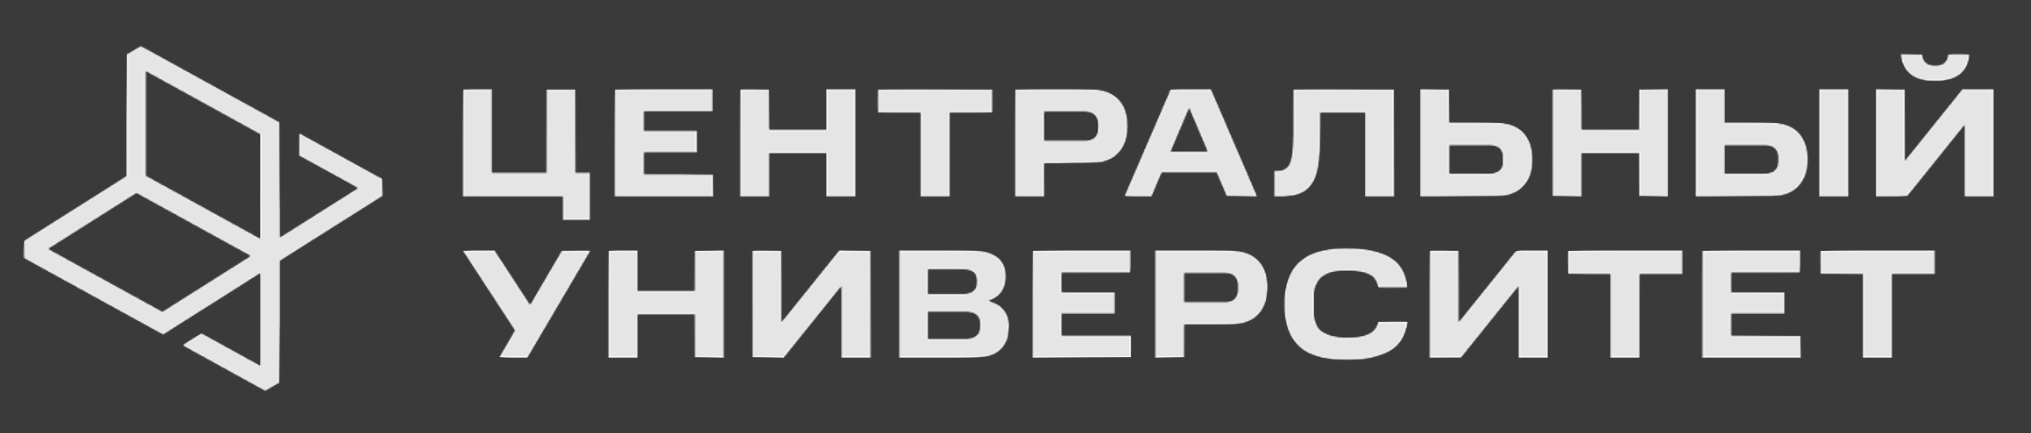


# Курс по Глубокому обучению


## Домашнее задание 7. Классификация текстов с LSTM (10 баллов + 2 бонусных балла)


# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки с разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются комментарием YOUR CODE HERE
    ❌ В заданиях на реализацию ответы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если не сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблицы - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

Перед сдачей перезапустите ядро и выполните ноутбук по порядку. Сохраните результаты, графики и выводы. Бонусные задания необязательны: если не выполняете бонус, оставьте `RUN_BONUS=False`.

Работу необходимо выполнить самостоятельно. Для заимствованных фрагментов кода и дополнительных материалов укажите источники.


**ФИО:** Чуриков Дмитрий Вадимович

**Группа:**


## О задании

Стандартный поток.

Будем определять тональность англоязычных сообщений о коронавирусе. В данных пять классов: от крайне отрицательной до крайне положительной тональности. Нужно подготовить тексты, собрать словарь, реализовать LSTM-классификатор и оценить его на отложенной выборке. В бонусе добавим внимание к скрытым состояниям.

В этой работе разберём, как рекуррентная сеть обрабатывает последовательность и формирует представление текста. Готовые классификаторы из внешних библиотек использовать нельзя.

Каждая задача имеет «стоимость» в баллах. Рекомендуем выполнять задания по порядку.


<font color='OrangeRed'>**Обратите внимание!**</font> Для обучения вам, вероятно, понадобится возможность работы с GPU. Можно использовать локальное окружение, Google Colab или Kaggle. Наличие CUDA проверяется ниже; на CPU код также работает, но обучение занимает больше времени.


<font color='OrangeRed'>**Обратите внимание!**</font> В Google Colab откройте меню «Среда выполнения», затем «Сменить среду выполнения» и выберите доступный GPU, например T4. После смены среды выполните ячейки с начала.


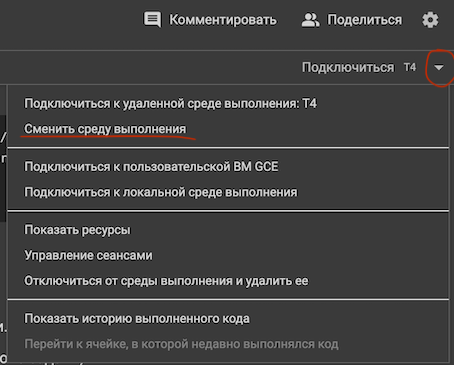


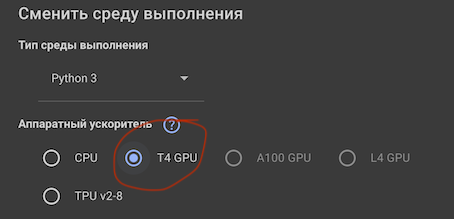


---

# Задание


## Подготовка окружения

Используйте Python 3.10 или новее и PyTorch 2.6 или новее. Если библиотеки ниже не установлены, раскомментируйте команду установки. PyTorch с поддержкой вашей видеокарты устанавливайте отдельно по [официальной инструкции](https://pytorch.org/get-started/locally/).


In [1]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.1,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "nltk>=3.8,<4" "gdown>=5,<6"
%pip install -q torch


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import random
import re
import zipfile

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.tokenize import TweetTokenizer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| устройство:", device)


PyTorch: 2.14.1+cu130 | устройство: cuda


## Данные

Используем [Coronavirus tweets NLP](https://www.kaggle.com/datasets/datatattle/covid-19-nlp-text-classification): столбец `OriginalTweet` содержит текст, `Sentiment` — метку тональности. Ссылку на архив даём ниже. Если автоматическая загрузка недоступна, скачайте архив по этой ссылке и положите его в `DATA_DIR` либо поместите туда оба CSV-файла.

Из исходного обучающего файла выделяем валидацию. По ней выбираем параметры и эпоху обучения. Тестовый файл используем только после выбора модели. Полные совпадения текстов удаляем до разбиения; тест сохраняем отдельно. Метки теста не используются для построения словаря и обучения.


In [3]:
DATA_DIR = Path("data_hw06_text")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_URL = "https://drive.google.com/uc?id=145ZCFU-b65Xbjsh16fPepF_N66X0kZj2"
csv_names = ["Corona_NLP_train.csv", "Corona_NLP_test.csv"]
if not all((DATA_DIR / name).is_file() for name in csv_names):
    archive = DATA_DIR / "coronavirus_archive.zip"
    if not archive.is_file():
        result = gdown.download(ARCHIVE_URL, str(archive), quiet=False)
        if result is None:
            raise RuntimeError("Скачайте архив по ARCHIVE_URL и поместите его в DATA_DIR.")
    with zipfile.ZipFile(archive) as z:
        for name in csv_names:
            candidates = [member for member in z.namelist() if Path(member).name == name]
            if len(candidates) != 1:
                raise ValueError(f"В архиве не найден единственный файл {name}.")
            (DATA_DIR / name).write_bytes(z.read(candidates[0]))

LABELS = ["Extremely Negative", "Negative", "Neutral", "Positive", "Extremely Positive"]
label_to_id = {label: i for i, label in enumerate(LABELS)}

def read_frame(path):
    frame = pd.read_csv(path, encoding="ISO-8859-1")[["OriginalTweet", "Sentiment"]].dropna()
    frame["OriginalTweet"] = frame["OriginalTweet"].astype(str).str.strip()
    frame = frame.loc[frame["OriginalTweet"].ne("")].copy()
    frame["text_key"] = frame["OriginalTweet"].str.lower().str.replace(r"\s+", " ", regex=True)
    # Удаляем неоднозначную разметку одинаковых текстов.
    n_labels = frame.groupby("text_key")["Sentiment"].transform("nunique")
    frame = frame.loc[n_labels.eq(1)].drop_duplicates("text_key").copy()
    assert set(frame["Sentiment"]).issubset(label_to_id), "Неизвестные метки классов."
    frame["label"] = frame["Sentiment"].map(label_to_id).astype(int)
    return frame.reset_index(drop=True)

source_train = read_frame(DATA_DIR / csv_names[0])
test_frame = read_frame(DATA_DIR / csv_names[1])
source_train = source_train.loc[~source_train["text_key"].isin(test_frame["text_key"])].copy()
train_frame, val_frame = train_test_split(
    source_train, test_size=0.15, stratify=source_train["label"], random_state=SEED
)
train_frame = train_frame.reset_index(drop=True)
val_frame = val_frame.reset_index(drop=True)
assert set(train_frame["text_key"]).isdisjoint(val_frame["text_key"])
assert set(train_frame["text_key"]).isdisjoint(test_frame["text_key"])
assert set(val_frame["text_key"]).isdisjoint(test_frame["text_key"])
print({name: len(frame) for name, frame in
       [("train", train_frame), ("validation", val_frame), ("test", test_frame)]})
display(train_frame[["OriginalTweet", "Sentiment"]].head())


{'train': 34969, 'validation': 6172, 'test': 3798}


,OriginalTweet,Sentiment
0,the new type of flex during #COVID2019 is talk...,Positive
1,@roblee7 @mikedarch @MattChorley Ok hypothetic...,Neutral
2,I would love to practice social distancing but...,Extremely Positive
3,On the bright side. \r\r\n\r\r\nAt least we'll...,Positive
4,This is how long the line is to get into the g...,Neutral


## <font color='DarkOrange'> **Задание 1. Подготовка текстов [1 балл]** </font>

Реализуйте `tokenize`. Приведите текст к нижнему регистру, удалите ссылки и упоминания пользователей. Для разбиения используйте готовый `TweetTokenizer`. Уберите знак решётки в начале хештега; оставьте токены, содержащие хотя бы одну латинскую букву. Остальные токены, в том числе отдельные числа и знаки препинания, удалите.

Стоп-слова удалять не будем: отрицания и короткие служебные слова могут влиять на тональность. Лемматизация здесь не обязательна. Функция должна принимать строку и возвращать список строк. Для пустого текста верните пустой список.

Токенизируйте три выборки. Постройте распределение длин на train и распределение классов. Кратко объясните, почему одной accuracy недостаточно для оценки качества.


In [4]:
"""
tweet_tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)

def tokenize(text):
    text = text.strip()
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"@\S+", "", text)
    text = text.replace("#","")
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return tweet_tokenizer.tokenize(text)
"""
tweet_tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)

def tokenize(text):
    text = text.lower()
    # Удаляем ссылки и упоминания пользователей
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    # Убираем символ # перед хештегами
    text = re.sub(r"#(\w+)", r"\1", text)
    
    tokens = tweet_tokenizer.tokenize(text)
    # Оставляем только токены, содержащие хотя бы одну латинскую букву
    return [tok for tok in tokens if re.search(r"[a-z]", tok)]

In [5]:
assert tokenize("") == []
assert tokenize("  @reader https://example.org 123 !!! ") == []
assert tokenize("Not #Happy") == ["not", "happy"]
assert tokenize("I can't agree") != tokenize("I can agree")
for frame in (train_frame, val_frame, test_frame):
    frame["tokens"] = frame["OriginalTweet"].map(tokenize)
display(train_frame[["OriginalTweet", "tokens"]].head(3))

,OriginalTweet,tokens
0,the new type of flex during #COVID2019 is talk...,"[the, new, type, of, flex, during, covid, is, ..."
1,@roblee7 @mikedarch @MattChorley Ok hypothetic...,"[ok, hypothetical, situation, you, have, had, ..."
2,I would love to practice social distancing but...,"[i, would, love, to, practice, social, distanc..."


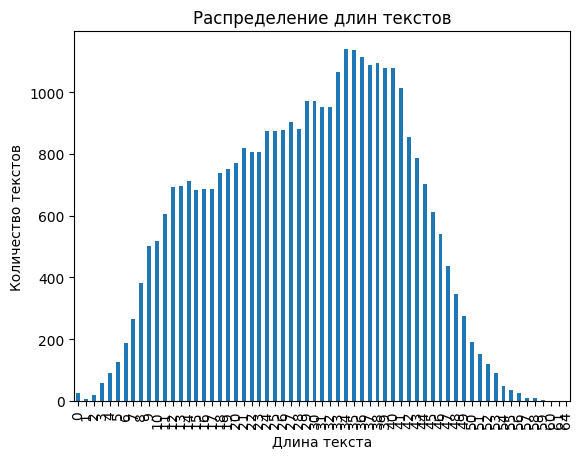

In [6]:
import matplotlib.pyplot as plt
# Построение распределения длин
lengths = train_frame["tokens"].map(len)
lengths.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Длина текста')
plt.ylabel('Количество текстов')
plt.title('Распределение длин текстов')
plt.show()

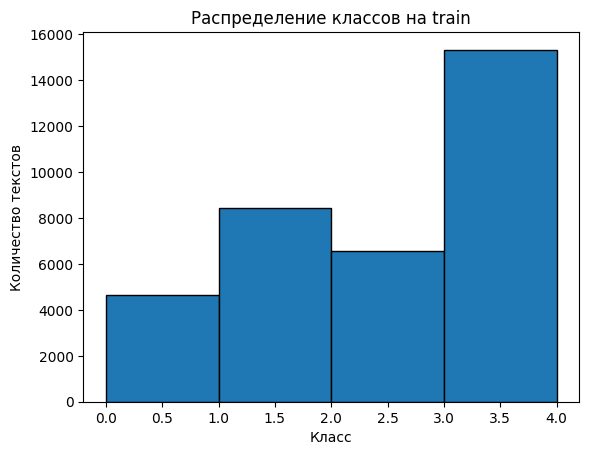

In [7]:
#Постройте распределение распределение классов на train
plt.hist(train_frame['label'], bins=4, edgecolor='black')
plt.xlabel('Класс')
plt.ylabel('Количество текстов')
plt.title('Распределение классов на train')
plt.show()

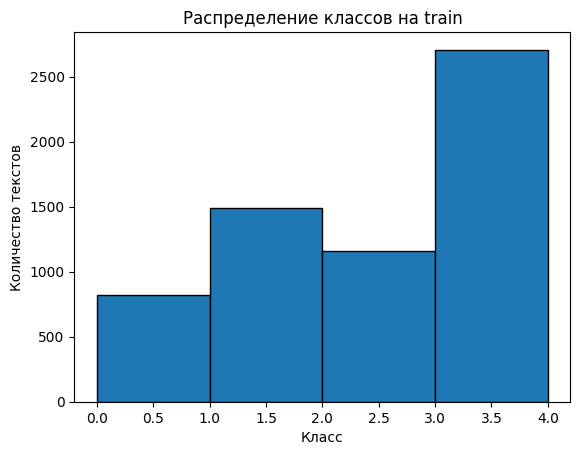

In [8]:
plt.hist(val_frame['label'], bins=4, edgecolor='black')
plt.xlabel('Класс')
plt.ylabel('Количество текстов')
plt.title('Распределение классов на train')
plt.show()

<font color='MediumOrchid'>**Ваш ответ в этой ячейке:**</font>

объясните, почему одной accuracy недостаточно для оценки качества:

accuracy недостоверно при дисбалансе классов



## <font color='DarkOrange'> **Задание 2. Словарь [1 балл]** </font>

Соберите счётчик токенов только по train. Реализуйте функцию `make_vocab`, которая возвращает список `itos` и словарь `stoi`.

Первые два элемента: `<pad>` с индексом 0 и `<unk>` с индексом 1. Далее идут токены по убыванию частоты; при равной частоте используйте алфавитный порядок. Максимальный размер словаря включает специальные токены. Счётчик нельзя изменять внутри функции. Неизвестные слова при кодировании получают индекс `<unk>`.

Используйте максимум 20 000 токенов и минимальную частоту 2. Посчитайте долю неизвестных токенов среди всех токенов каждой выборки. Объясните, почему нельзя пополнить словарь словами из теста перед оценкой.


In [17]:
PAD_ID, UNK_ID = 0, 1
"""
def make_vocab(counter, max_size=20_000, min_freq=2):
    # Фильтруем по min_freq и сортируем: сначала по убыванию частоты (-freq), затем по алфавиту (token)
    filtered = [
        (token, freq) for token, freq in counter.items() if freq >= min_freq
    ]
    filtered.sort(key=lambda item: (-item[1], item[0]))
    
    # Оставляем место под <pad> и <unk>
    vocab = [token for token, _ in filtered[:max(0, max_size - 2)]]
    itos = ["<pad>", "<unk>"] + vocab
    stoi = {token: i for i, token in enumerate(itos)}
    return itos, stoi

# Собираем счётчик по train и обновляем ОСНОВНЫЕ itos и stoi
counter = Counter()
for tokens in train_frame["tokens"]:
    counter.update(tokens)

itos, stoi = make_vocab(counter, max_size=20_000, min_freq=2)
print("Размер основного словаря:", len(itos))
"""
def make_vocab(counter, max_size=20_000, min_freq=2):
    filtered = [
        (token, freq) for token, freq in counter.items() if freq >= min_freq
    ]
    # Сортировка: сначала по убыванию частоты (-freq), затем по алфавиту (token)
    filtered.sort(key=lambda item: (-item[1], item[0]))
    
    vocab = [token for token, _ in filtered[:max(0, max_size - 2)]]
    itos = ["<pad>", "<unk>"] + vocab
    stoi = {token: i for i, token in enumerate(itos)}
    return itos, stoi

# Собираем счётчик по train и записываем в основные itos, stoi
counter = Counter()
for tokens in train_frame["tokens"]:
    counter.update(tokens)

itos, stoi = make_vocab(counter, max_size=20_000, min_freq=2)
print("Размер словаря:", len(itos))

Размер словаря: 19813


In [18]:
small_counter = Counter({"z": 4, "a": 4, "rare": 1})
before = small_counter.copy()
small_itos, small_stoi = make_vocab(small_counter, max_size=4, min_freq=2)
assert small_itos == ["<pad>", "<unk>", "a", "z"]
assert small_counter == before
assert small_stoi["z"] == 3 and len(small_stoi) == len(small_itos)
assert len(stoi) == len(itos) <= 20_000 and stoi["<pad>"] == PAD_ID
assert set(stoi) - {"<pad>", "<unk>"} <= set(counter)
print("Размер словаря:", len(itos))

Размер словаря: 19813


In [19]:
#Посчитайте долю неизвестных токенов среди всех токенов каждой выборки.
datasets = {
    "train_frame": train_frame,
    "val_frame": val_frame,
    "test_frame": test_frame,
}

for name, frame in datasets.items():
    frame["tokens"] = frame["OriginalTweet"].map(tokenize)
    frame["unknown_tokens"] = frame["tokens"].map(
        lambda tokens: [token for token in tokens if token not in small_stoi]
    )
    frame["unknown_tokens_count"] = frame["unknown_tokens"].map(len)
    frame["total_tokens_count"] = frame["tokens"].map(len)
    
    # Общая доля неизвестных токенов среди всех токенов выборки
    total_unknown = frame["unknown_tokens_count"].sum()
    total_tokens = frame["total_tokens_count"].sum()
    overall_ratio = total_unknown / total_tokens
    
    print(f"Доля неизвестных токенов в {name}: {overall_ratio:.2%}")
    print(f"Количество неизвестных токенов в {name}: {total_unknown}")
    print(f"Количество всех токенов в {name}: {total_tokens}")
    print(f"Количество текстов с неизвестными токенами в {name}: {frame['unknown_tokens_count'].gt(0).sum()}")
    print(f"Количество текстов без неизвестных токенов в {name}: {frame['unknown_tokens_count'].eq(0).sum()}")
    print("-" * 50)

Доля неизвестных токенов в train_frame: 98.37%
Количество неизвестных токенов в train_frame: 998308
Количество всех токенов в train_frame: 1014833
Количество текстов с неизвестными токенами в train_frame: 34943
Количество текстов без неизвестных токенов в train_frame: 26
--------------------------------------------------
Доля неизвестных токенов в val_frame: 98.35%
Количество неизвестных токенов в val_frame: 174927
Количество всех токенов в val_frame: 177860
Количество текстов с неизвестными токенами в val_frame: 6167
Количество текстов без неизвестных токенов в val_frame: 5
--------------------------------------------------
Доля неизвестных токенов в test_frame: 98.48%
Количество неизвестных токенов в test_frame: 118829
Количество всех токенов в test_frame: 120658
Количество текстов с неизвестными токенами в test_frame: 3796
Количество текстов без неизвестных токенов в test_frame: 2
--------------------------------------------------


<font color='MediumOrchid'>**Ваш ответ в этой ячейке:**</font>

Объясните, почему нельзя пополнить словарь словами из теста перед оценкой.

Это приведет к утечке данных, так как модель будет обучаться на данных, которые она не видела до этого. Это может привести к переобучению модели и снижению ее производительности на новых данных.

## <font color='DarkOrange'> **Задание 3. Dataset и сборка батча [1.5 балла]** </font>

Реализуйте `TextDataset` и `collate_batch`. Используйте уже готовые списки токенов из столбца `tokens`: повторно токенизировать их не нужно.

Обрезайте текст до `max_len=200`. Пустой список заменяйте одним `<unk>`, чтобы длина была положительной. Один объект датасета — словарь: `tokens` (одномерный LongTensor) и `label` (целое число).

В батче должны быть `tokens` размера `(batch, time)`, `lengths` размера `(batch,)` и `labels` размера `(batch,)`. Все три тензора имеют тип `torch.long`. Дополняйте последовательности справа индексом `<pad>`, сохраняйте исходный порядок объектов.


In [20]:
PAD_ID = 0
UNK_ID = 1
class TextDataset(Dataset):
    def __init__(self, frame, stoi, max_len=200):
        self.frame = frame.reset_index(drop=True)
        self.stoi = stoi
        self.max_len = max_len

    def __len__(self):
        return len(self.frame)
        
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        tokens = row["tokens"][:self.max_len]
        
        # Если список токенов пустой, подставляем ["<unk>"]
        if not tokens:
            tokens = ["<unk>"]
            
        token_ids = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        tokens_tensor = torch.tensor(token_ids, dtype=torch.long)
        label_tensor = torch.tensor(row["label"], dtype=torch.long)
        return tokens_tensor, label_tensor

def collate_batch(samples):
    # Извлекаем токены и метки в зависимости от формата элемента батча
    if isinstance(samples[0], dict):
        tokens = [s["tokens"] for s in samples]
        labels = [s["label"] for s in samples]
    else:
        tokens, labels = zip(*samples)
        tokens = list(tokens)
        labels = list(labels)

    lengths = torch.tensor([len(t) for t in tokens], dtype=torch.long)
    padded_tokens = pad_sequence(tokens, batch_first=True, padding_value=PAD_ID)
    
    # Используем torch.tensor вместо torch.stack, чтобы работало и с int, и с Tensor
    labels_tensor = torch.tensor(labels, dtype=torch.long)

    # Возвращаем словарь с ключами, которые ожидает run_epoch ("tokens", "lengths", "labels")
    return {
        "tokens": padded_tokens,
        "lengths": lengths,
        "labels": labels_tensor
    }

In [21]:
toy_frame = pd.DataFrame({"tokens": [["a", "outside", "z"], []], "label": [3, 0]})
toy_ds = TextDataset(toy_frame, small_stoi, max_len=2)
toy_batch = collate_batch([toy_ds[0], toy_ds[1]])
assert len(toy_ds) == 2
assert toy_batch["tokens"].tolist() == [[2, UNK_ID], [UNK_ID, PAD_ID]]
assert toy_batch["lengths"].tolist() == [2, 1]
assert toy_batch["labels"].tolist() == [3, 0]
assert all(x.dtype == torch.long for x in toy_batch.values())

train_ds = TextDataset(train_frame, stoi)
val_ds = TextDataset(val_frame, stoi)
test_ds = TextDataset(test_frame, stoi)
BATCH_SIZE = 64

def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    options = dict(batch_size=BATCH_SIZE, collate_fn=collate_batch, num_workers=0)
    return (
        DataLoader(train_ds, shuffle=True, generator=generator, **options),
        DataLoader(val_ds, shuffle=False, **options),
        DataLoader(test_ds, shuffle=False, **options),
    )

train_loader, val_loader, test_loader = make_loaders()


## <font color='DarkOrange'> **Задание 4. LSTM-классификатор [2 балла]** </font>

Реализуйте `LSTMClassifier` со следующими слоями:

1. `Embedding`: размер словаря `vocab_size`, размерность `emb_dim`, `padding_idx=PAD_ID`.
2. Однослойная двунаправленная `LSTM` с размером скрытого состояния `hidden_dim` в каждом направлении и `batch_first=True`.
3. `Dropout` и линейный классификатор из `2 * hidden_dim` признаков в `n_classes` логитов.

Для обработки последовательностей разной длины используйте `pack_padded_sequence` с `enforce_sorted=False`. Длины передавайте на CPU. Объедините последние скрытые состояния прямого и обратного направлений из `h_n`. При наличии паддинга последний столбец дополненного тензора не соответствует последнему токену каждого текста.

Для слоя эмбеддингов используйте атрибут `embedding`, для LSTM — `lstm`, для Dropout — `dropout`, для линейного классификатора — `classifier`. Эти имена понадобятся в бонусном подклассе.

Метод `forward(tokens, lengths)` возвращает логиты размера `(batch, n_classes)`. Softmax перед `CrossEntropyLoss` не нужен.


In [22]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden_dim=128, n_classes=5, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=emb_dim,
            padding_idx=PAD_ID
        )
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(2 * hidden_dim, n_classes)

    def forward(self, tokens, lengths):
        # Получаем эмбеддинги: (batch, seq_len, emb_dim)
        embedded = self.embedding(tokens)
        
        # Упаковываем последовательности, перенося lengths на CPU
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )
        
        # Прогоняем через LSTM; h_n имеет форму (num_directions, batch, hidden_dim) -> (2, batch, hidden_dim)
        _, (h_n, _) = self.lstm(packed)
        
        # Объединяем последние скрытые состояния прямого (h_n[0]) и обратного (h_n[1]) проходов
        hidden = torch.cat((h_n[0], h_n[1]), dim=1)  # (batch, 2 * hidden_dim)
        
        # Применяем регуляризацию и линейный слой
        out = self.dropout(hidden)
        logits = self.classifier(out)  # (batch, n_classes)
        
        return logits


In [23]:
check_model = LSTMClassifier(12, emb_dim=8, hidden_dim=7, dropout=0).to(device)
check_tokens = torch.tensor([[2, 3, 4], [5, 0, 0]], device=device)
check_lengths = torch.tensor([3, 1])
check_model.eval()
with torch.no_grad():
    logits = check_model(check_tokens, check_lengths)
    extra_pad = nn.functional.pad(check_tokens, (0, 4), value=PAD_ID)
    assert logits.shape == (2, 5) and torch.isfinite(logits).all()
    torch.testing.assert_close(logits, check_model(extra_pad, check_lengths), atol=1e-4, rtol=1e-4)
    torch.testing.assert_close(logits[1:], check_model(check_tokens[1:, :1], check_lengths[1:]),
                               atol=1e-4, rtol=1e-4)
check_model.train()
nn.functional.cross_entropy(check_model(check_tokens, check_lengths),
                            torch.tensor([0, 4], device=device)).backward()
assert check_model.embedding.weight.grad[2:].abs().sum() > 0
assert torch.count_nonzero(check_model.embedding.weight.grad[PAD_ID]) == 0
assert all(p.grad is not None and torch.isfinite(p.grad).all()
           for p in check_model.parameters())
del check_model


## <font color='DarkOrange'> **Задание 5. Обучение и оценка [1.5 балла]** </font>

Реализуйте `run_epoch`. Если передан оптимизатор, выполните одну эпоху обучения, иначе — оценку. Переключайте `train()` и `eval()`, отключайте вычисление градиентов при оценке. Обнуляйте градиенты перед каждым шагом, используйте `CrossEntropyLoss` и ограничение нормы градиента `max_norm=1.0`.

Верните словарь с полями `loss`, `f1`, `targets`, `predictions`. В `targets` и `predictions` сохраните одномерные массивы NumPy с истинными метками и предсказанными классами в порядке обхода загрузчика. Loss усредняется по объектам, а не по числу батчей. Macro-F1 вычисляется по всем предсказаниям за эпоху, для всех пяти классов; для случаев, когда метрика не определена, используйте `zero_division=0`.


In [24]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score


def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    
    criterion = nn.CrossEntropyLoss(reduction="sum")
    device = next(model.parameters()).device
    
    total_loss = 0.0
    total_samples = 0
    all_targets = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for batch in loader:
            # Поддержка форматов батча: (tokens, lengths, labels) или словарь
            if isinstance(batch, dict):
                tokens = batch["tokens"].to(device)
                lengths = batch["lengths"]
                labels = batch["labels"].to(device)
            else:
                tokens, lengths, labels = batch
                tokens = tokens.to(device)
                labels = labels.to(device)
                
            if is_train:
                optimizer.zero_grad()
                
            logits = model(tokens, lengths)
            loss = criterion(logits, labels)
            
            if is_train:
                # Делим на размер батча для корректного масштаба градиентов при шаге оптимизатора
                batch_loss = loss / labels.size(0)
                batch_loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                
            total_loss += loss.item()
            total_samples += labels.size(0)
            
            preds = logits.argmax(dim=1)
            all_targets.append(labels.detach().cpu().numpy())
            all_predictions.append(preds.detach().cpu().numpy())
            
    targets_np = np.concatenate(all_targets)
    predictions_np = np.concatenate(all_predictions)
    
    avg_loss = total_loss / total_samples
    macro_f1 = f1_score(
        targets_np,
        predictions_np,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )
    
    return {
        "loss": avg_loss,
        "f1": macro_f1,
        "targets": targets_np,
        "predictions": predictions_np
    }


In [25]:
check_model = LSTMClassifier(12, emb_dim=8, hidden_dim=7, dropout=0).to(device)
check_samples = [{"tokens": torch.tensor([2, 3]), "label": 0},
                 {"tokens": torch.tensor([4]), "label": 1},
                 {"tokens": torch.tensor([5, 6, 7]), "label": 4}]
loader_a = DataLoader(check_samples, batch_size=2, collate_fn=collate_batch)
loader_b = DataLoader(check_samples, batch_size=3, collate_fn=collate_batch)
weights_before = deepcopy(check_model.state_dict())
result_a, result_b = run_epoch(check_model, loader_a), run_epoch(check_model, loader_b)
assert np.isclose(result_a["loss"], result_b["loss"], atol=1e-4)
assert result_a["targets"].tolist() == [0, 1, 4]
assert 0 <= result_a["f1"] <= 1
assert all(torch.equal(value, weights_before[name]) for name, value in check_model.state_dict().items())
optimizer_check = torch.optim.Adam(check_model.parameters(), lr=0.01)
run_epoch(check_model, loader_a, optimizer_check)
assert any(not torch.equal(value, weights_before[name])
           for name, value in check_model.state_dict().items())
del check_model, optimizer_check


## <font color='DarkOrange'> **Задание 6. Эксперимент [1.5 балла]** </font>

Обучите базовую модель. Начните с параметров ниже; при необходимости меняйте их по результатам валидации. Проведите не более трёх основных запусков, не считая отладки на нескольких батчах. За один запуск используйте не более 15 эпох.

Создайте модель в переменной `model`. Функция `fit` должна возвращать `pandas.DataFrame`; сохраните его в `history`. Столбцы: `epoch`, `train_loss`, `val_loss`, `train_f1`, `val_f1`.

После каждой эпохи сохраняйте loss и macro-F1 для train и validation. Выберите веса с наибольшим validation macro-F1. Если качество не улучшилось за три последовательные эпохи, остановите обучение. Копия лучших весов должна быть независимой от последующих обновлений модели.

Постройте графики loss и macro-F1. Укажите, как выбиралась эпоха и заметно ли переобучение. В этом разделе не вычисляйте качество на тесте.


In [26]:
EPOCHS = 12
PATIENCE = 3
MODEL_CONFIG = dict(vocab_size=len(itos), emb_dim=128, hidden_dim=128, n_classes=5, dropout=0.3)
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

In [27]:
from copy import deepcopy
import pandas as pd
import torch

EPOCHS = 12
PATIENCE = 3
MODEL_CONFIG = dict(vocab_size=len(itos), emb_dim=128, hidden_dim=128, n_classes=5, dropout=0.3)
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

def fit(model, train_loader, val_loader, epochs=EPOCHS):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )
    
    best_val_f1 = -1.0
    best_weights = deepcopy(model.state_dict())
    patience_counter = 0
    
    records = []
    
    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, optimizer=optimizer)
        val_metrics = run_epoch(model, val_loader, optimizer=None)
        
        records.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_f1": train_metrics["f1"],
            "val_loss": val_metrics["loss"],
            "val_f1": val_metrics["f1"]
        })
        
        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {train_metrics['loss']:.4f}, Train F1: {train_metrics['f1']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f}, Val F1: {val_metrics['f1']:.4f}"
        )
        
        if val_metrics["f1"] > best_val_f1:
            best_val_f1 = val_metrics["f1"]
            best_weights = deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping на эпохе {epoch}. Лучший Val F1: {best_val_f1:.4f}")
                break
                
    model.load_state_dict(best_weights)
    return pd.DataFrame(records)

model = LSTMClassifier(**MODEL_CONFIG).to(device)
history = fit(model, train_loader, val_loader, epochs=EPOCHS)

Epoch 01/12 | Train Loss: 1.4066, Train F1: 0.3661 | Val Loss: 1.2353, Val F1: 0.4845
Epoch 02/12 | Train Loss: 1.0398, Train F1: 0.5835 | Val Loss: 0.9898, Val F1: 0.6136
Epoch 03/12 | Train Loss: 0.7630, Train F1: 0.7177 | Val Loss: 0.8623, Val F1: 0.6742
Epoch 04/12 | Train Loss: 0.5653, Train F1: 0.8020 | Val Loss: 0.8222, Val F1: 0.7043
Epoch 05/12 | Train Loss: 0.4199, Train F1: 0.8586 | Val Loss: 0.8230, Val F1: 0.7203
Epoch 06/12 | Train Loss: 0.2994, Train F1: 0.9029 | Val Loss: 0.8922, Val F1: 0.7231
Epoch 07/12 | Train Loss: 0.2109, Train F1: 0.9328 | Val Loss: 0.9750, Val F1: 0.7259
Epoch 08/12 | Train Loss: 0.1543, Train F1: 0.9509 | Val Loss: 1.1227, Val F1: 0.7209
Epoch 09/12 | Train Loss: 0.1099, Train F1: 0.9662 | Val Loss: 1.1800, Val F1: 0.7240
Epoch 10/12 | Train Loss: 0.0807, Train F1: 0.9753 | Val Loss: 1.3378, Val F1: 0.7166
Early stopping на эпохе 10. Лучший Val F1: 0.7259


In [28]:
assert len(history) > 0 and np.isfinite(history.select_dtypes("number").to_numpy()).all()
restored_result = run_epoch(model, val_loader)
assert np.isclose(restored_result["f1"], history["val_f1"].max(), atol=1e-8)
assert restored_result["f1"] >= 0.60, "Качество низкое: проверьте подготовку данных и обучение."

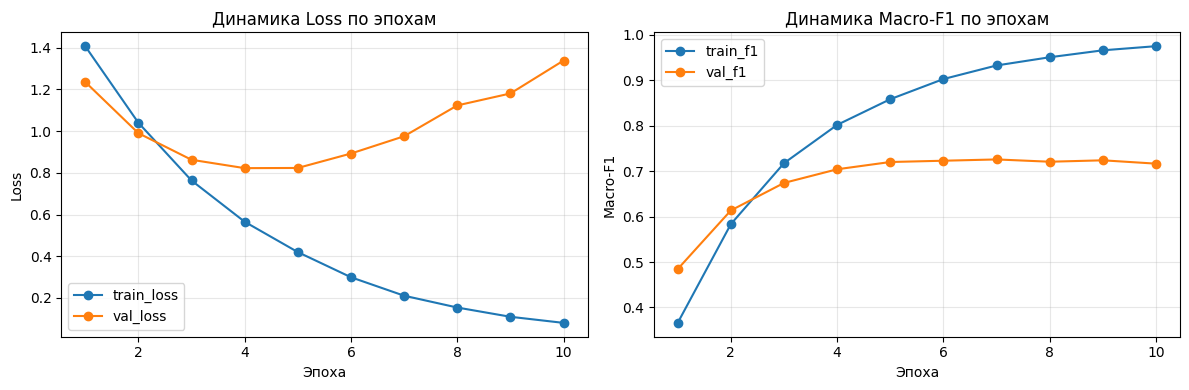

In [31]:
#Постройте графики loss и macro-F1. Укажите, как выбиралась эпоха и заметно ли переобучение. В этом разделе не вычисляйте качество на тесте.
# Построение графиков loss и macro-F1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train_loss")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="val_loss")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].set_title("Динамика Loss по эпохам")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(history["epoch"], history["train_f1"], marker="o", label="train_f1")
axes[1].plot(history["epoch"], history["val_f1"], marker="o", label="val_f1")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Динамика Macro-F1 по эпохам")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


<font color='MediumOrchid'>**Ваш ответ в этой ячейке:**</font>

...


## <font color='DarkOrange'> **Задание 7. Качество и разбор ошибок [1.5 балла]** </font>

Один раз оцените выбранную модель на test. Сохраните словарь, возвращённый `run_epoch`, в переменной `test_result`. Выведите macro-F1, отчёт по классам и матрицу ошибок с нормировкой по истинному классу. Выведите пять ошибочно классифицированных текстов вместе с истинной и предсказанной метками. Выбирайте первые ошибки в порядке тестовой выборки, не подбирайте только удобные примеры.

За корректную оценку и разбор ошибок предусмотрен 1 балл. Ещё 0.5 балла — за test macro-F1 не ниже 0.65. Это целевое качество работы, а не гарантия для любого набора гиперпараметров. Не подбирайте параметры по тесту. Проверки внизу включают порог macro-F1, но не оценивают полноту разбора ошибок.

Какие классы модель путает? Достаточно ли отдельных слов для определения тональности во всех приведённых примерах?


In [ ]:
# YOUR CODE HERE
raise NotImplementedError


In [ ]:
assert len(test_result["predictions"]) == len(test_ds)
assert np.isfinite(test_result["loss"]) and 0 <= test_result["f1"] <= 1
assert test_result["f1"] >= 0.65, "Проверьте качество на тесте и согласованность обработки текстов."


<font color='MediumOrchid'>**Ваш ответ в этой ячейке:**</font>

...


## <font color='MediumSeaGreen'> **Бонус. Внимание к скрытым состояниям [2 балла]** </font>

Замените объединение последних состояний на взвешенную сумму всех выходов двунаправленной LSTM. Для каждого состояния примените линейный слой с одним выходом, затем softmax по времени. Перед softmax исключите паддинг. Классификатор получает взвешенную сумму состояний.

Реализуйте `AttentionLSTMClassifier` с теми же аргументами конструктора. Метод `forward` возвращает логиты, а при `return_attention=True` — пару из логитов и весов внимания. Используйте `pad_packed_sequence(..., batch_first=True, total_length=tokens.size(1))`.

Обучите модель по тому же протоколу и сравните с базовой по валидации. Меняется только способ агрегирования состояний, остальные параметры и разбиения одинаковые. Покажите веса внимания для трёх валидационных текстов. Объясните, почему большой вес внимания нельзя считать доказательством причинного влияния слова. За реализацию и проверки — 1 балл, за эксперимент и выводы — 1 балл.

Чтобы выполнить бонусные ячейки, установите `RUN_BONUS=True`.


In [ ]:
RUN_BONUS = False


In [ ]:
class AttentionLSTMClassifier(LSTMClassifier):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        # YOUR CODE HERE
        raise NotImplementedError

    def forward(self, tokens, lengths, return_attention=False):
        # YOUR CODE HERE
        raise NotImplementedError


In [ ]:
if RUN_BONUS:
    attention_check = AttentionLSTMClassifier(vocab_size=12, emb_dim=8, hidden_dim=7, dropout=0).to(device).eval()
    with torch.no_grad():
        attention_logits, weights = attention_check(check_tokens, check_lengths, return_attention=True)
        assert weights.shape == check_tokens.shape
        torch.testing.assert_close(weights.sum(dim=1), torch.ones(2, device=device))
        assert torch.count_nonzero(weights[1, 1:]) == 0
        torch.testing.assert_close(attention_logits,
                                   attention_check(nn.functional.pad(check_tokens, (0, 3)), check_lengths),
                                   atol=1e-6, rtol=1e-5)
    del attention_check


In [ ]:
if RUN_BONUS:
    # YOUR CODE HERE
    raise NotImplementedError


<font color='MediumOrchid'>**Ваш ответ в этой ячейке:**</font>

...
